# 06 - Is Each Foot Above the Flood Line Worth It?

**DSC 411/511 Semester Project** · Venkat Repaka, Ritik Gaire

**Question:** How much less damage does a building get for each foot its lowest floor is **above the base flood elevation**?

- The **base flood elevation (BFE)** is the height that flood water has a 1% chance to reach in any year (the "100-year flood").
- `elevationDifference` = height of the lowest floor **minus** the BFE, in whole feet. +3 means the floor is 3 feet above the flood line,
  -2 means 2 feet below it.
- Building higher than the BFE is called **freeboard**. Owners and towns have to decide if it is worth the extra cost.

We measure the damage with the **damage ratio** (building damage ÷ building value, from notebook 01), so that big and small buildings can be
compared.

**Plan**
1. Prepare the data: which claims have an elevation difference?
2. The damage curve: damage ratio for each foot
3. A puzzle: why is damage low far *below* the flood line?
4. A fair comparison: same zone, same kind of building, same storm
5. A model: how much does one foot change the damage ratio?
6. Our answer

## 1. Prepare the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
SEED = 42

df = pd.read_parquet('data/claims_clean.parquet')
raw = pd.read_parquet('/Users/home/workspace/School/DataMining/project/NfipClaimsV3.parquet', columns=['id', 'elevationDifference'])
df = df.merge(raw, on='id', how='left')
df['elevationDifference'] = df['elevationDifference'].astype(float)
df.loc[df['elevationDifference'].abs() >= 500, 'elevationDifference'] = np.nan     # 999 / 9999 placeholders (see notebook 01)

FOUNDATION_NAMES = {'1': 'slab', '2': 'basement', '3': 'crawlspace', '4': 'elevated (4)', '5': 'elevated (5)', '6': 'elevated (6)', '0': 'not recorded'}
df['foundation_name'] = df['foundation'].map(FOUNDATION_NAMES).fillna('unknown')
df['elevated_type'] = np.where(df['foundation'].isin(['4', '5', '6']), 'elevated', np.where(df['foundation'] == '1', 'slab', 'other'))

has_ed = df['elevationDifference'].notna()
has_ratio = df['damage_ratio'].notna()
print(f'Claims: {len(df):,}')
print(f'   with an elevation difference           : {has_ed.sum():,} ({has_ed.mean():.0%})')
print(f'   with an elevation difference AND ratio : {(has_ed & has_ratio).sum():,}')
print(df.loc[has_ed, 'elevationDifference'].describe(percentiles=[0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99]).round(1))

Claims: 276,570
   with an elevation difference           : 94,445 (34%)
   with an elevation difference AND ratio : 73,388
count    94445.0
mean         0.3
std          5.3
min       -254.0
1%          -9.0
5%          -6.0
25%         -2.0
50%          0.0
75%          2.0
95%          6.0
99%          9.0
max        451.0
Name: elevationDifference, dtype: float64


**Who has an elevation difference?** The value comes from an **elevation certificate**, which not every building has.
If the buildings with a certificate are different from the others, our result only describes *them*. So we compare the two groups.

In [2]:
grp = np.where(has_ed, 'has elevation difference', 'no elevation difference')
compare = pd.DataFrame({
    'claims': pd.Series(grp).value_counts(),
    'median building age': df.groupby(grp)['building_age'].median(),
    'share in zone AE': df.groupby(grp)['zone'].apply(lambda s: (s == 'AE').mean()),
    'share in zone X': df.groupby(grp)['zone'].apply(lambda s: (s == 'X').mean()),
    'share elevated foundation': df.groupby(grp)['elevated_type'].apply(lambda s: (s == 'elevated').mean()),
    'share in Florida': df.groupby(grp)['state'].apply(lambda s: (s == 'FL').mean()),
    'median damage ratio': df.groupby(grp)['damage_ratio'].median()})
compare.T.round(2)

,has elevation difference,no elevation difference
claims,94445.00,182125.00
median building age,35.60,52.77
share in zone AE,0.88,0.63
share in zone X,0.02,0.28
share elevated foundation,0.34,0.11
share in Florida,0.63,0.51
median damage ratio,0.07,0.20


**What we see**
- **94,445 claims (34%)** have an elevation difference, and 73,388 also have a damage ratio. Half of them are between 2 feet below and
  2 feet above the flood line; the extreme values (like -254 or +451 feet) are surely errors, so we will only use -6 to +10 feet.
- **The claims with an elevation difference are different from the others:** newer buildings (median age 36 vs 53 years), almost all in
  zone AE (88% vs 63%, only 2% in zone X), more often elevated (34% vs 11%) and more often in Florida (63% vs 51%). Their median damage ratio
  is also much lower (7% vs 20%).
- So our answer describes **buildings with an elevation certificate**, mostly newer buildings inside the mapped floodplain. It may not be true
  for old buildings in zone X.

## 2. The damage curve

We keep claims with an elevation difference from **-6 to +10 feet** (98% of them; the rest are rare and very far from the line)
and compute, for each whole foot:
- the **median damage ratio** (a typical claim),
- the share of claims with **major or severe** damage (over 25% of the building value),
- how many claims there are (so we know which points are reliable).

Claims in the curve: 69,396


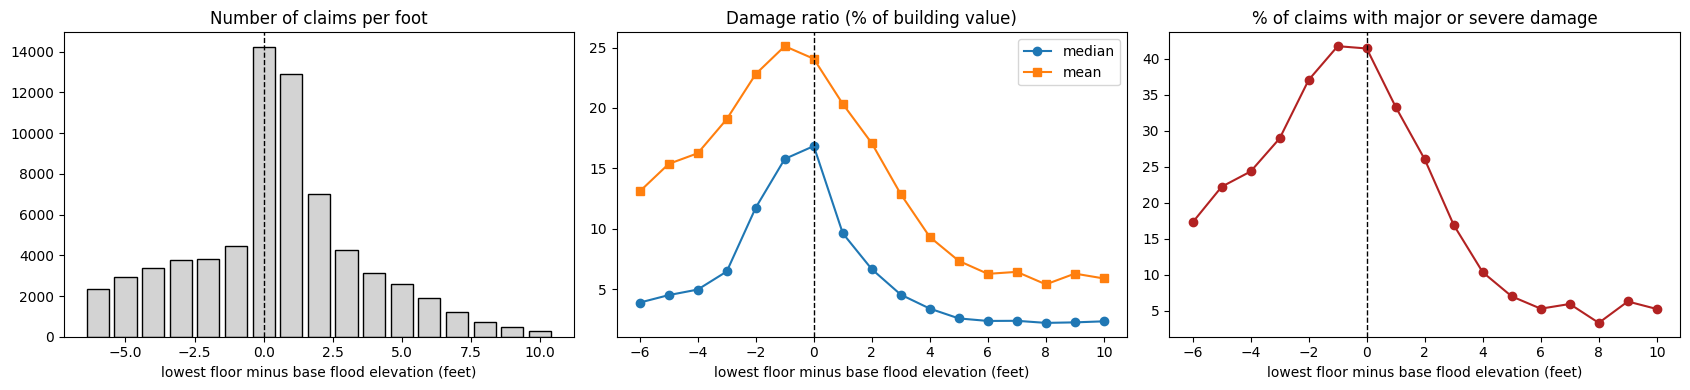

,claims,median_ratio,mean_ratio,major_or_severe
ft,,,,
-6,2327,0.039,0.131,0.173
-5,2934,0.045,0.154,0.222
-4,3364,0.050,0.162,0.243
-3,3784,0.065,0.191,0.289
-2,3805,0.117,0.228,0.371
-1,4446,0.158,0.251,0.417
0,14238,0.168,0.241,0.414
1,12886,0.096,0.203,0.333
2,6988,0.066,0.171,0.260


In [3]:
d = df[has_ed & has_ratio & df['elevationDifference'].between(-6, 10)].copy()
d['ft'] = d['elevationDifference'].astype(int)
d['major_or_severe'] = (d['damage_ratio'] > 0.25).astype(int)
curve = d.groupby('ft').agg(claims=('id', 'size'), median_ratio=('damage_ratio', 'median'),
                            mean_ratio=('damage_ratio', 'mean'), major_or_severe=('major_or_severe', 'mean'))
print(f'Claims in the curve: {len(d):,}')

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
ax[0].bar(curve.index, curve['claims'], color='lightgray', edgecolor='black'); ax[0].set_title('Number of claims per foot')
ax[1].plot(curve.index, curve['median_ratio'] * 100, marker='o', label='median'); ax[1].plot(curve.index, curve['mean_ratio'] * 100, marker='s', label='mean')
ax[1].set_title('Damage ratio (% of building value)'); ax[1].legend()
ax[2].plot(curve.index, curve['major_or_severe'] * 100, marker='o', color='firebrick'); ax[2].set_title('% of claims with major or severe damage')
for a in ax:
    a.axvline(0, color='black', ls='--', lw=1); a.set_xlabel('lowest floor minus base flood elevation (feet)')
plt.tight_layout(); plt.show()
curve.round(3)

**What we see**
- **Above the flood line, the damage falls quickly with every foot.** The median damage ratio is **16.8%** at 0 feet, **9.6%** at +1 foot,
  **6.6%** at +2 feet and **3.4%** at +4 feet. After about +5 feet it stays flat at about 2-3%.
- The share of claims with **major or severe** damage falls from **41%** at 0 feet to **26%** at +2 feet and about **5-7%** at +5 feet and higher.
- **The first two feet give the biggest gain.** Going from 0 to +2 feet cuts the median damage ratio by more than half; after +5 feet one more
  foot hardly changes anything.
- **Strange:** *below* the flood line the damage goes **down** again (3.9% at -6 feet). A floor far under the flood line should get more water,
  not less. We check this in the next section.

## 3. A puzzle: why is damage low far *below* the flood line?

The curve goes **up** from -6 to about 0 feet, which is the opposite of what we expected: a floor far below the flood line should get
*more* water. We look at **which buildings** are in each part of the curve.

In [4]:
d['position'] = pd.cut(d['ft'], bins=[-7, -3, -1, 0, 2, 10], labels=['-6 to -3 ft', '-2 to -1 ft', '0 ft', '+1 to +2 ft', '+3 to +10 ft'])
mix = pd.crosstab(d['position'], d['foundation_name'], normalize='index')
mix = mix[[c for c in ['basement', 'slab', 'crawlspace', 'elevated (4)', 'elevated (5)', 'elevated (6)', 'not recorded'] if c in mix.columns]]
extra = d.groupby('position', observed=True).agg(claims=('id', 'size'), median_ratio=('damage_ratio', 'median'),
                                                 zone_V=('zone', lambda s: (s == 'V').mean()),
                                                 median_coverage=('totalBuildingInsuranceCoverage', 'median'))
(mix * 100).round(0).join(extra.round(3))

,basement,slab,crawlspace,elevated (4),elevated (5),elevated (6),not recorded,claims,median_ratio,zone_V,median_coverage
position,,,,,,,,,,,
-6 to -3 ft,8.0,24.0,9.0,1.0,27.0,21.0,8.0,12409,0.050,0.051,250000.0
-2 to -1 ft,3.0,51.0,17.0,2.0,10.0,7.0,9.0,8251,0.141,0.020,250000.0
0 ft,1.0,75.0,6.0,5.0,3.0,2.0,7.0,14238,0.168,0.019,250000.0
+1 to +2 ft,1.0,63.0,6.0,11.0,6.0,4.0,8.0,19874,0.080,0.031,250000.0
+3 to +10 ft,1.0,17.0,5.0,26.0,24.0,19.0,9.0,14624,0.030,0.100,250000.0


In [5]:
print('Median damage ratio by foot, slab and basement buildings only:')
sb = d[d['foundation_name'].isin(['slab', 'basement'])]
print(sb.pivot_table(index='ft', columns='foundation_name', values='damage_ratio', aggfunc='median').round(3).loc[-6:3].to_string())

Median damage ratio by foot, slab and basement buildings only:


foundation_name  basement   slab
ft                              
-6                  0.061  0.424
-5                  0.058  0.392
-4                  0.061  0.384
-3                  0.050  0.395
-2                  0.051  0.360
-1                  0.055  0.321
 0                  0.055  0.216
 1                  0.065  0.124
 2                  0.056  0.087
 3                  0.042  0.052


**What we see.** The puzzle is a **mix effect**: the buildings in the different parts of the curve are not the same kind of building.
- At **0 feet**, 75% of the claims are **slab** buildings. At **-6 to -3 feet**, only 24% are slab; the biggest groups are **elevated buildings
  with an enclosure** (elevated (5) and (6), together 48%) and basements (8%).
- For an elevated building with an enclosure, the "lowest floor" in the data can be the floor of the enclosure (a garage or storage area under the
  house), which is below the flood line, while the rooms people live in are higher up. For a basement, NFIP covers only a few things in the
  basement. In both cases the measured floor is low, but the damage paid on the building is small.
- **When we look at slab buildings only, the curve makes sense:** the median damage ratio is **42%** at -6 feet, **36%** at -2 feet, **22%** at
  0 feet, **12%** at +1 and **5%** at +3 feet. The deeper the floor is below the flood line, the worse the damage.
- So we must compare **the same kind of building**. This is a good example of why one overall curve can mislead.

## 4. A fair comparison

A building high above the flood line may also be **newer**, in a **different zone** or hit by a **weaker storm**. To make the comparison
fairer we draw the curve **inside groups** where these things are the same:
- zone AE only, slab buildings vs elevated buildings;
- the three biggest storms (Helene, Ian, Ida) separately.

We only use the part from **0 to +8 feet** (the floor at or above the flood line), where the curve should go down.

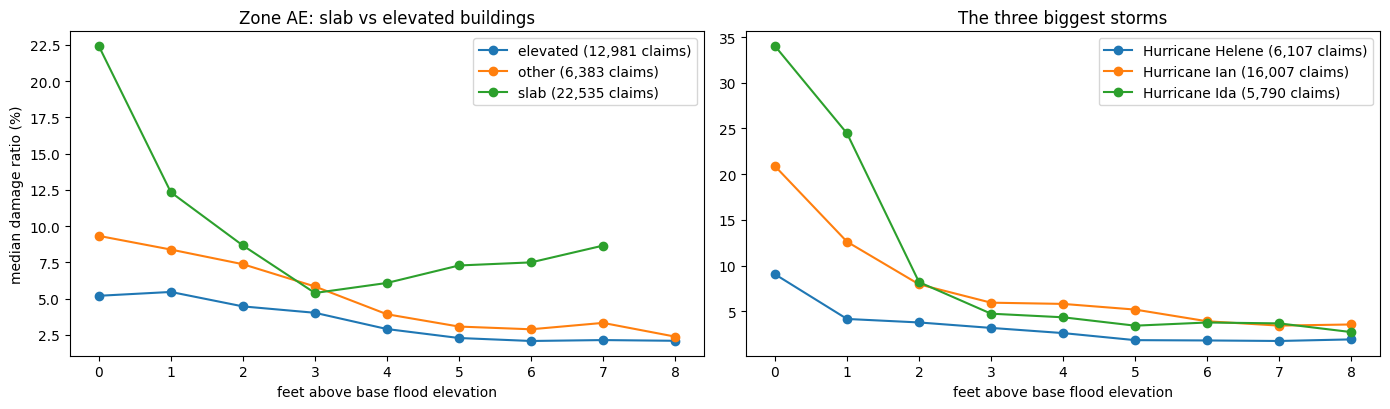

,claims,median at 0 ft,median at +2 ft,median at +4 to +8 ft,drop from 0 to +2 ft
group,,,,,
all claims,47976,0.168,0.066,0.027,0.606
"zone AE, slab",22535,0.224,0.087,0.066,0.614
"zone AE, elevated",12981,0.052,0.045,0.024,0.141
Hurricane Helene,6107,0.091,0.038,0.020,0.582
Hurricane Ian,16007,0.209,0.080,0.048,0.619
Hurricane Ida,5790,0.340,0.082,0.037,0.759


In [6]:
up = d[d['ft'].between(0, 8)]
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for name, g in up[up['zone'] == 'AE'].groupby('elevated_type'):
    c = g.groupby('ft')['damage_ratio'].agg(['median', 'size'])
    c = c[c['size'] >= 50]
    ax[0].plot(c.index, c['median'] * 100, marker='o', label=f'{name} ({len(g):,} claims)')
ax[0].set_title('Zone AE: slab vs elevated buildings'); ax[0].set_xlabel('feet above base flood elevation'); ax[0].set_ylabel('median damage ratio (%)'); ax[0].legend()
for storm in ['Hurricane Helene', 'Hurricane Ian', 'Hurricane Ida']:
    g = up[up['floodEvent'] == storm]
    c = g.groupby('ft')['damage_ratio'].agg(['median', 'size'])
    c = c[c['size'] >= 50]
    ax[1].plot(c.index, c['median'] * 100, marker='o', label=f'{storm} ({len(g):,} claims)')
ax[1].set_title('The three biggest storms'); ax[1].set_xlabel('feet above base flood elevation'); ax[1].legend()
plt.tight_layout(); plt.show()

rows = []
for label, g in [('all claims', up)] + [(f'zone AE, {t}', up[(up['zone'] == 'AE') & (up['elevated_type'] == t)]) for t in ['slab', 'elevated']] + \
                [(s, up[up['floodEvent'] == s]) for s in ['Hurricane Helene', 'Hurricane Ian', 'Hurricane Ida']]:
    at0 = g.loc[g['ft'] == 0, 'damage_ratio'].median()
    at2 = g.loc[g['ft'] == 2, 'damage_ratio'].median()
    at4 = g.loc[g['ft'].between(4, 8), 'damage_ratio'].median()
    rows.append({'group': label, 'claims': len(g), 'median at 0 ft': at0, 'median at +2 ft': at2, 'median at +4 to +8 ft': at4,
                 'drop from 0 to +2 ft': 1 - at2 / at0 if at0 else np.nan})
pd.DataFrame(rows).set_index('group').round(3)

**What we see**
- **Slab buildings in zone AE:** median damage ratio **22%** at 0 feet and **8.7%** at +2 feet, a drop of **61%**. Above +4 feet it is 6.6%.
- **Elevated buildings in zone AE** already have little damage at 0 feet (5.2%), so extra feet change less (4.5% at +2 feet, a drop of 14%).
  This makes sense: for these buildings the living area is already above the measured floor.
- **The same pattern in every big storm:** going from 0 to +2 feet cuts the median damage ratio by **58%** in Helene, **62%** in Ian and
  **76%** in Ida. The level is different (Ida 34% at 0 feet, Helene 9%), but the drop is similar.
- So the effect is **not** caused by one storm or one zone: building above the flood line helps in all of them, most for slab buildings.

## 5. A model: how much does one foot change the damage ratio?

We fit a **linear regression** on the claims from **0 to +8 feet**: damage ratio = a + b × (feet above BFE) + other features.
The other features keep the comparison fair: flood zone, foundation, occupancy, building age, state group, loss year and the storm.
The coefficient **b** is the change in the damage ratio for **one more foot**, with the other features held the same.

To see how sure we can be about **b**, we use a **bootstrap**: we draw the claims again with replacement 200 times, fit the model each time,
and look at the middle 95% of the 200 values of b.

In [7]:
from sklearn.linear_model import LinearRegression

top_states = up['state'].value_counts().head(8).index
top_storms = up['floodEvent'].value_counts().head(10).index
m = up.assign(state_group=up['state'].where(up['state'].isin(top_states), 'other'),
              storm=up['floodEvent'].where(up['floodEvent'].isin(top_storms), 'other / none'))
Xr = pd.get_dummies(m[['ft', 'building_age', 'loss_year', 'zone', 'foundation_name', 'occupancy', 'state_group', 'storm']],
                    columns=['zone', 'foundation_name', 'occupancy', 'state_group', 'storm'], drop_first=True, dtype=float)
yr = m['damage_ratio']

simple = LinearRegression().fit(m[['ft']], yr)
full = LinearRegression().fit(Xr, yr)
print(f'Claims in the model: {len(m):,}')
print(f'Only feet as feature  : each foot changes the damage ratio by {simple.coef_[0] * 100:+.2f} percentage points')
print(f'With all other features: each foot changes the damage ratio by {full.coef_[list(Xr.columns).index("ft")] * 100:+.2f} percentage points')

rng = np.random.default_rng(SEED)
boot = []
for _ in range(200):
    i = rng.integers(0, len(Xr), len(Xr))
    boot.append(LinearRegression().fit(Xr.iloc[i], yr.iloc[i]).coef_[list(Xr.columns).index('ft')])
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f'Bootstrap 95% interval for one foot: {lo * 100:+.2f} to {hi * 100:+.2f} percentage points')

value = m['buildingPropertyValue'].median()
print(f'\nMedian building value of these claims: ${value:,.0f}')
print(f'So one foot is worth about ${-full.coef_[list(Xr.columns).index("ft")] * value:,.0f} less damage for a typical building in one flood.')

Claims in the model: 47,976
Only feet as feature  : each foot changes the damage ratio by -2.95 percentage points
With all other features: each foot changes the damage ratio by -1.46 percentage points


Bootstrap 95% interval for one foot: -1.54 to -1.36 percentage points

Median building value of these claims: $250,068
So one foot is worth about $3,650 less damage for a typical building in one flood.


**What we see**
- With **only the feet** as a feature, each foot above the flood line goes with **2.95 percentage points** less damage ratio.
- With **all the other features** (zone, foundation, occupancy, age, state, year, storm), the effect is about half: **-1.46 points per foot**.
  Part of the simple effect came from the other differences (for example, buildings high above the line are more often elevated and newer).
- The **bootstrap interval is narrow** (-1.54 to -1.36 points), so we are quite sure the effect is real and about this size.
- For a typical building in these claims (value about **$250,000**), one foot is worth about **$3,650 less damage in one flood**.
- **Be careful:** a straight line gives the *average* effect from 0 to +8 feet. The curve in section 2 shows that the first feet are worth
  much more than the last ones, so the gain for the first 1-2 feet is bigger than 1.46 points per foot.

## 6. Our answer

| Lowest floor vs flood line | Median damage ratio (all claims) | Slab buildings only | Major or severe damage |
|---|---|---|---|
| at the flood line (0 ft) | 16.8% | 21.6% | 41% |
| +1 foot | 9.6% | 12.4% | 33% |
| +2 feet | 6.6% | 8.7% | 26% |
| +4 feet | 3.4% | - | 10% |

> **Yes, especially the first two feet.** For claims with an elevation certificate, the median damage ratio falls from 16.8% at the flood
> line to 6.6% at 2 feet above it, and to about 2-3% at 5 feet and more. The drop from 0 to +2 feet is about 60% in zone AE slab buildings and
> in each of the big storms (Helene, Ian, Ida). With zone, foundation, building type, age, place and storm held the same, each foot above the
> flood line goes with about **1.5 percentage points less damage** (95% interval 1.4 to 1.5), which is about **$3,650 for a typical building in
> one flood**. After about +5 feet, more height adds little.

**What we learned:** one overall curve can mislead. Below the flood line the damage looked *lower*, but only because that part of the curve is
full of elevated buildings with enclosures and basements. Looking at one kind of building (slab) gave the expected result.

**Limits**
- Only 34% of claims have an elevation difference; they are mostly newer buildings in zone AE, so the result may not hold for old buildings in zone X.
- We only see buildings that **had** a claim. Buildings high enough to stay dry never appear in the data, so the real benefit of height is
  probably **bigger** than what we measure.
- This is a comparison, not an experiment: buildings built higher may also differ in ways we cannot see (for example newer building rules).